# EDA — bộ hợp đồng lao động mẫu

Mục tiêu: kiểm tra bộ hợp đồng tự tạo có dùng được làm test set cho rule engine không —
phủ những điều khoản nào, các con số trong hợp đồng nằm ở đâu so với ngưỡng luật,
và có đủ hợp đồng "sạch" để đo false positive không.

In [1]:
import re
import math
from pathlib import Path
from dataclasses import asdict

import pandas as pd
import matplotlib.pyplot as plt

from ingest import process_batch

# bảng màu dùng chung cho mọi chart
BLUE, RED, INK, MUTED, GRID, SURFACE = "#2a78d6", "#d03b3b", "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
})

In [2]:
clauses = process_batch(Path("data/contracts"))
df = pd.DataFrame([asdict(c) for c in clauses])
df["so_tu"] = df["text"].str.split().str.len()
df.head()

,contract_id,dieu_so,tieu_de,text,so_tu
0,HD_001,1,CÔNG VIỆC VÀ ĐỊA ĐIỂM LÀM VIỆC,Người lao động làm việc vị trí Kế toán viên; n...,30
1,HD_001,2,LOẠI VÀ THỜI HẠN HỢP ĐỒNG,"Loại hợp đồng: không xác định thời hạn, có hiệ...",14
2,HD_001,3,"THỜI GIỜ LÀM VIỆC, NGHỈ NGƠI","Thời giờ làm việc 08 giờ/ngày, 48 giờ/tuần, ng...",34
3,HD_001,4,LƯƠNG VÀ PHỤ CẤP,Mức lương theo công việc: 9.000.000 đồng/tháng...,19
4,HD_001,5,HÌNH THỨC VÀ KỲ HẠN TRẢ LƯƠNG,"Trả lương bằng chuyển khoản, 01 lần/tháng vào ...",25


## 1. Cấu trúc — có file nào bị cắt hụt không?

In [3]:
n_hd = df["contract_id"].nunique()
print(f"{len(df)} điều khoản / {n_hd} hợp đồng — trung bình {len(df)/n_hd:.2f} Điều/HĐ")
print("\nSố Điều mỗi HĐ:")
print(df.groupby("contract_id").size().value_counts().sort_index().to_string())
print("\nĐộ dài điều khoản (số từ):")
print(df["so_tu"].describe().round(1).to_string())

593 điều khoản / 50 hợp đồng — trung bình 11.86 Điều/HĐ

Số Điều mỗi HĐ:
11     7
12    43

Độ dài điều khoản (số từ):
count    593.0
mean      31.7
std       10.9
min       13.0
25%       22.0
50%       32.0
75%       37.0
max       67.0


Đọc kết quả: nếu có HĐ nào số Điều lệch hẳn so với phần còn lại, hoặc `so_tu` có giá trị
cực lớn (2-3 Điều dính làm một) / cực nhỏ (bắt nhầm dòng không phải heading),
thì quay lại chỉnh `DIEU_PATTERN` trong `ingest.py`.

## 2. Độ phủ — mỗi loại điều khoản có mặt ở bao nhiêu hợp đồng?

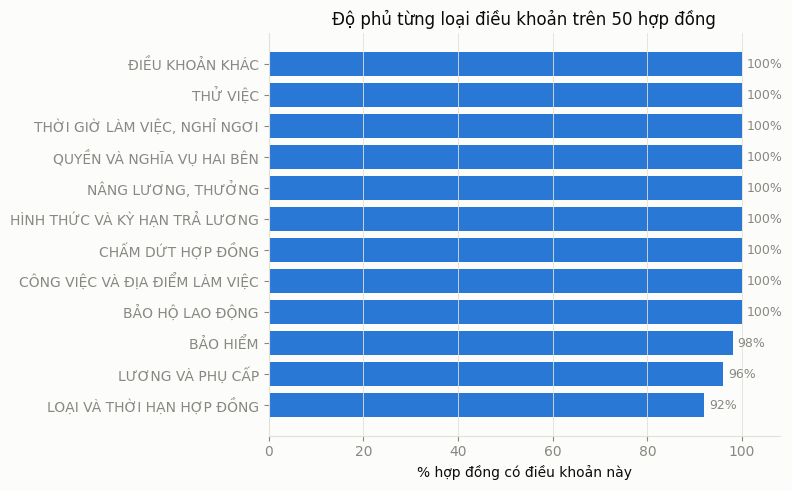

In [4]:
cover = (df.groupby("tieu_de")["contract_id"].nunique() / n_hd * 100).sort_values()
lech = cover[cover < 100]

if len(lech) < 2:
    print(f"{len(cover) - len(lech)}/{len(cover)} loại điều khoản có mặt ở cả {n_hd} HĐ → không cần vẽ.")
    if len(lech):
        print("Không đủ 100%: " + ", ".join(f"{k} ({v:.0f}%)" for k, v in lech.items()))
else:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(cover.index, cover.values, color=BLUE)
    for y, v in enumerate(cover.values):
        ax.text(v + 1, y, f"{v:.0f}%", va="center", color=MUTED, fontsize=9)
    ax.set_xlim(0, 108)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("% hợp đồng có điều khoản này")
    ax.set_title(f"Độ phủ từng loại điều khoản trên {n_hd} hợp đồng")
    fig.tight_layout()
    plt.show()

## 3. Trích số liệu từng hợp đồng (test luôn regex sắp dùng cho rule engine)

In [5]:
FIELDS = {
    "luong_thang":    r"([\d.]{7,})\s*đồng/tháng",
    "gio_tuan":       r"(\d{1,2})\s*giờ/tuần",
    "gio_ngay":       r"(\d{1,2})\s*giờ/ngày",
    "lam_them_thang": r"(\d{1,3})\s*giờ/tháng",
    "thu_viec_ngay":  r"thử việc\s+(\d{1,3})\s*ngày",
    "thu_viec_pct":   r"(\d{2,3})\s*%\s*mức lương",
}

def max_num(text, pattern):
    """Lấy giá trị LỚN NHẤT khớp pattern — tránh bắt nhầm phụ cấp 730.000 thay cho lương."""
    vals = [int(x.replace(".", "")) for x in re.findall(pattern, text, re.IGNORECASE)]
    return max(vals) if vals else None

by_hd = df.groupby("contract_id")["text"].apply(" ".join)
num = pd.DataFrame({k: by_hd.map(lambda t, p=p: max_num(t, p)) for k, p in FIELDS.items()})

print("Độ phủ trích xuất:")
print(num.notna().sum().to_frame("số HĐ")
      .assign(**{"%": lambda d: (d["số HĐ"] / n_hd * 100).round(0)}).to_string())
num.describe().round(0)

Độ phủ trích xuất:
                số HĐ     %
luong_thang        38  76.0
gio_tuan           42  84.0
gio_ngay           42  84.0
lam_them_thang     43  86.0
thu_viec_ngay      43  86.0
thu_viec_pct        0   0.0


,luong_thang,gio_tuan,gio_ngay,lam_them_thang,thu_viec_ngay
count,38.0,42.0,42.0,43.0,43.0
mean,12763158.0,49.0,8.0,43.0,54.0
std,3927961.0,3.0,0.0,10.0,35.0
min,4000000.0,48.0,8.0,40.0,30.0
25%,10000000.0,48.0,8.0,40.0,30.0
50%,12000000.0,48.0,8.0,40.0,30.0
75%,15000000.0,48.0,8.0,40.0,60.0
max,18000000.0,60.0,10.0,80.0,120.0


Trường nào độ phủ thấp hơn kỳ vọng nghĩa là regex đó chưa bắt hết cách diễn đạt trong hợp đồng
— sửa pattern rồi chạy lại cell này cho tới khi đủ.
(`thu_viec_*` thấp là bình thường nếu một phần hợp đồng không có điều khoản thử việc.)

## 4. Giá trị thật so với ngưỡng luật

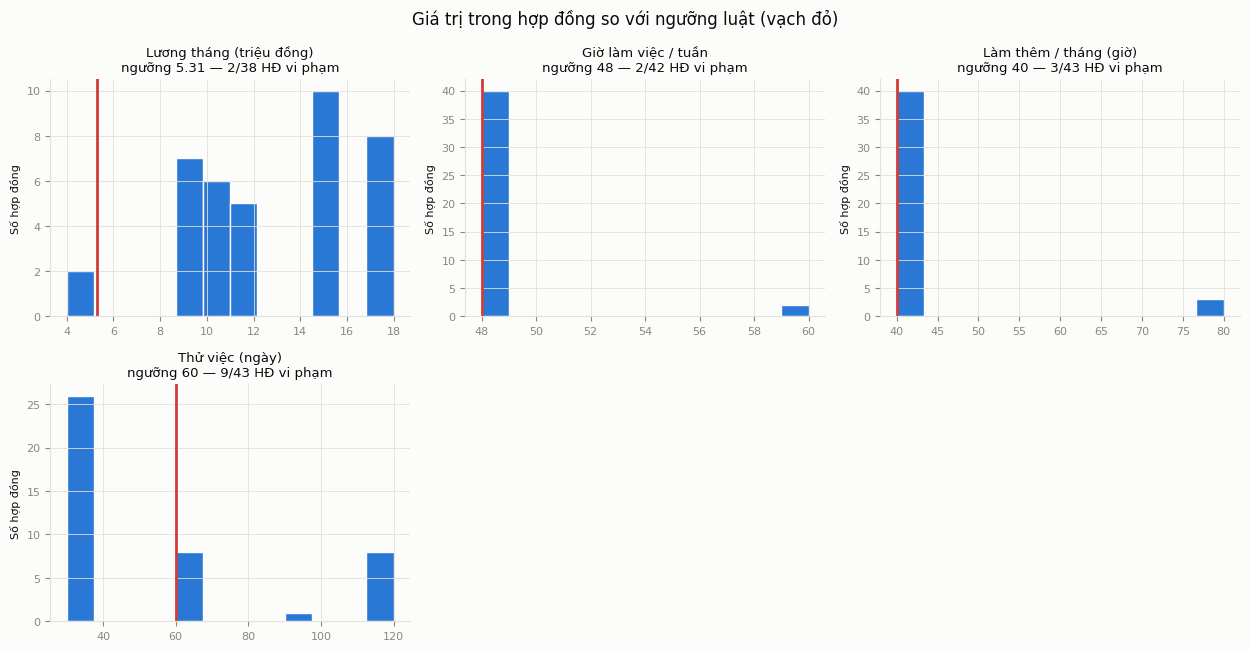

In [6]:
CHECKS = [  # khớp config/thresholds.yaml
    ("luong_thang",    5_310_000, "min", "Lương tháng (triệu đồng)", 1e6),
    ("gio_tuan",       48,        "max", "Giờ làm việc / tuần",      1),
    ("lam_them_thang", 40,        "max", "Làm thêm / tháng (giờ)",   1),
    ("thu_viec_ngay",  60,        "max", "Thử việc (ngày)",          1),
    ("thu_viec_pct",   85,        "min", "Lương thử việc (%)",       1),
]

avail = [c for c in CHECKS if num[c[0]].notna().any()]
ncol = min(3, len(avail))
nrow = math.ceil(len(avail) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.3 * nrow))
axes = list(axes.flat) if len(avail) > 1 else [axes]

vi_pham = pd.DataFrame(index=num.index)
for ax, (col, thr, kind, title, scale) in zip(axes, avail):
    s = num[col].dropna()
    bad = (s < thr) if kind == "min" else (s > thr)
    vi_pham[col] = bad.reindex(num.index)
    ax.hist(s / scale, bins=12, color=BLUE, edgecolor=SURFACE)
    ax.axvline(thr / scale, color=RED, linewidth=2)
    ax.set_title(f"{title}\nngưỡng {thr/scale:g} — {bad.sum()}/{len(s)} HĐ vi phạm", fontsize=9.5)
    ax.set_ylabel("Số hợp đồng", fontsize=8)
    ax.tick_params(labelsize=8)
for ax in axes[len(avail):]:
    ax.remove()

fig.suptitle("Giá trị trong hợp đồng so với ngưỡng luật (vạch đỏ)", fontsize=12)
fig.tight_layout()
plt.show()

## 5. Mỗi hợp đồng dính bao nhiêu lỗi định lượng?

Số HĐ không dính ngưỡng nào (ca âm): 36/50


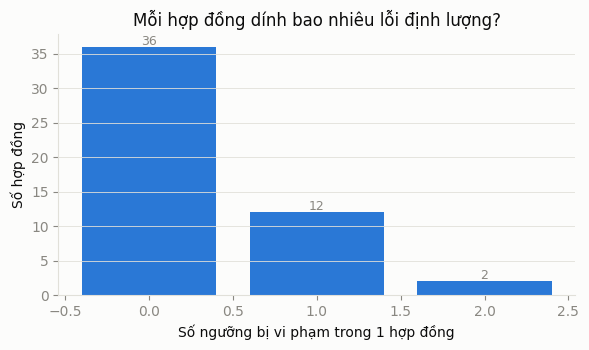

In [7]:
so_loi = vi_pham.fillna(False).sum(axis=1).astype(int)
print(f"Số HĐ không dính ngưỡng nào (ca âm): {(so_loi == 0).sum()}/{n_hd}")

vc = so_loi.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(vc.index, vc.values, color=BLUE)
for x, y in vc.items():
    ax.text(x, y + 0.3, str(y), ha="center", color=MUTED, fontsize=9)
ax.set_xlabel("Số ngưỡng bị vi phạm trong 1 hợp đồng")
ax.set_ylabel("Số hợp đồng")
ax.set_title("Mỗi hợp đồng dính bao nhiêu lỗi định lượng?")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

Nếu số HĐ "ca âm" bằng 0 (hợp đồng nào cũng có lỗi), test set chưa đo được false positive
— cần bổ sung vài hợp đồng hoàn toàn hợp lệ trước khi đánh giá rule engine.

## 6. Xuất bảng tổng hợp cho bước sau

In [8]:
ket_qua = num.copy()
ket_qua["so_loi_dinh_luong"] = so_loi
ket_qua.to_csv("data/eda_summary.csv", encoding="utf-8-sig")
print("Đã lưu data/eda_summary.csv")
ket_qua.head()

Đã lưu data/eda_summary.csv


,luong_thang,gio_tuan,gio_ngay,lam_them_thang,thu_viec_ngay,thu_viec_pct,so_loi_dinh_luong
contract_id,,,,,,,
HD_001,9000000.0,48.0,8.0,40.0,30.0,None,0
HD_002,18000000.0,48.0,8.0,40.0,30.0,None,0
HD_003,10000000.0,48.0,8.0,40.0,30.0,None,0
HD_004,9000000.0,48.0,8.0,40.0,30.0,None,0
HD_005,12000000.0,48.0,8.0,40.0,30.0,None,0
